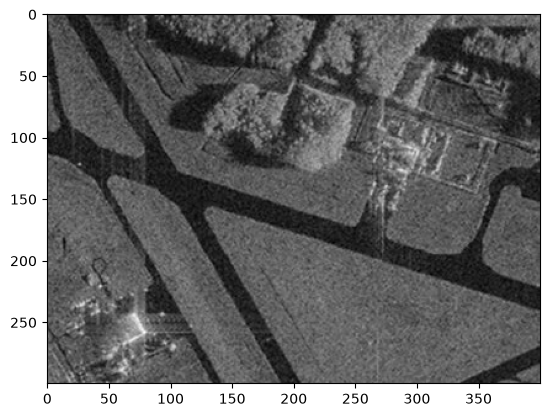

In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap="gray")

# 1. Подобрать параметры алгоритма разрастания регионов, чтобы был выделен весь участок газона.

# 1.1 Функция критерия однородности

In [5]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
    
    if abs(av_val - img[point]) <= T:
        return True
    
    return False

# 1.2 Функция разрастания регионов

In [6]:
def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask
    return mask*255

# 1.3 Подбор параметров под газон

In [ ]:
seed_point = (125, 125)
mask = region_growing(image_gray, seed_point, homo_average, 4, 22)

60
156
189
218
258
274
260
268
270
270
218
228
247
271
319
345
422
458
445
538
513
533
557
649
724
842
874
817
820
949
897
922
949
965
1011
1047
1167
1311
1448
1496
1543
1259
1256
1267
1634
1470
1629
1636
1668
1731
1786
1963
1562
1478
1472
1558
1573
1530
1643
1523
1590
2212
1680
1834
1979
1956
1859
1386
892
553
561
555
440
339
223
214
199
184
753
167
153
140
124
110
100
91
79
64
46
25
0


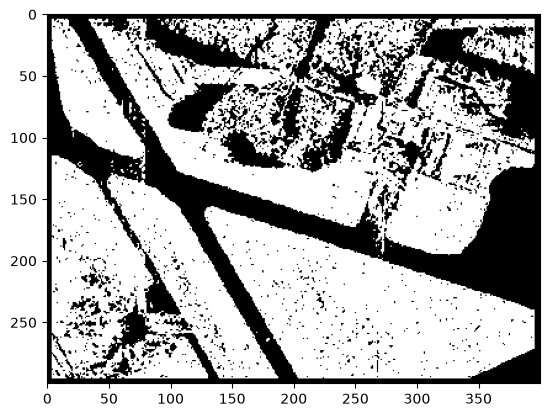

In [ ]:
plt.imshow(mask, cmap="gray")

# 2. Реализовать вычисление критерия однородности, отличного от представленного. Сравнить результаты.

In [7]:
def homo_local(img, mask, point, T):
    i, j = point
    r = 2
    
    neighborhood = img[max(0, i-r):i+r+1, max(0, j-r):j+r+1]
    av_val = neighborhood.mean()
    
    if abs(av_val - img[point]) <= T:
        return True
    
    return False

In [8]:
seed_point = (125, 125)
mask_local = region_growing(image_gray, seed_point, homo_local, 7, 8)

135
388
629
944
1142
1276
1581
1794
2003
2193
2468
2644
2842
2951
3341
3576
3801
3930
4142
3475
2275
2307
2443
2370
1293
1282
1297
1374
1352
1341
1313
1299
1186
1265
1342
1369
1483
1425
198
0


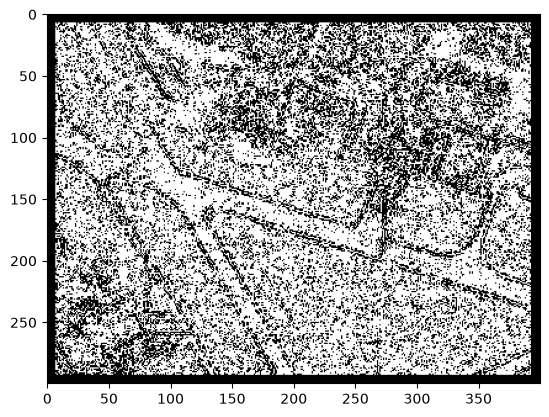

In [9]:
plt.imshow(mask_local, cmap="gray")

homo_average лучше: при сравнимом объеме пикселей он выделяет газон сплошной областью с четкими границами, в то время как homo_local создает шумную маску с пропусками внутри.

# 3. Применить алгоритм сегментации watershed + distance transform для задачи подсчета пальмовых деревьев

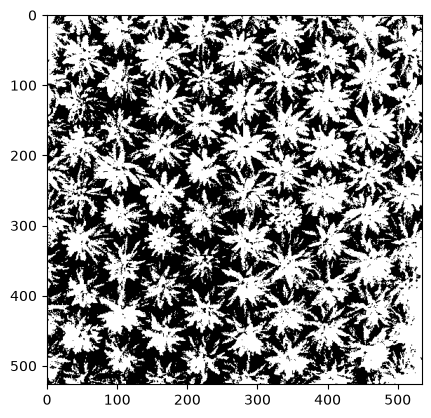

In [ ]:
image = cv2.imread('palm_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

ret, thresh = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)
plt.imshow(thresh, cmap="gray")

In [ ]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5) 
ret, sure_fg = cv2.threshold(dist, 0.4 * dist.max(), 255, cv2.THRESH_BINARY) 
sure_fg = sure_fg.astype(np.uint8)

51


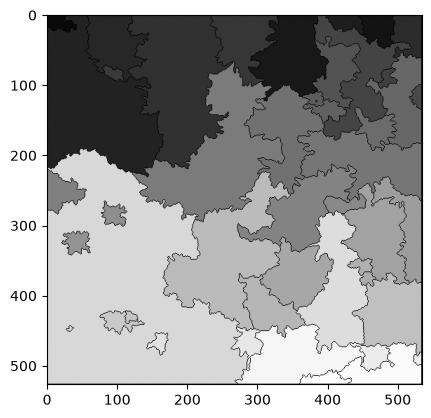

In [ ]:
ret, markers = cv2.connectedComponents(sure_fg)
markers = cv2.watershed(image, markers)
print(markers.max())
plt.imshow(markers, cmap="gray")